# Milestone 2, Section 2: fine-tuning the same-story model

Fine-tunes the multilingual MiniLM so that headlines about the same story end up close together and headlines about different stories end up far apart. It uses the pairs from `src/build_pairs.py` and the same evaluation as `src/baselines.py`, so the numbers sit in one table with the baselines.

1. Setup and versioned config
2. Data
3. Evaluation helpers (same rules as `baselines.py`: threshold picked on val, applied unchanged to test)
4. Training loop (PyTorch)
5. Learning curves
6. Test results on pairs, per edition
7. Grouping articles into cards, compared with Google's cards
8. Ablation: training on English pairs only
9. Training efficiency (for Section 3)

Outputs go to `outputs/milestone2/`. The trained model is saved to `models/minilm_finetuned/` (not committed: too large for GitHub).

Runs on the GPU automatically when one is available (CUDA or Apple MPS), otherwise on the CPU. Set `SMOKE = True` to check that everything runs in a few minutes before the full run.

In [1]:
import json, os, platform, random, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import sentence_transformers   # import before torch: the other order crashes on some Windows setups (DLL clash)
import torch
import transformers, sklearn
from sentence_transformers import SentenceTransformer, losses
from transformers import get_linear_schedule_with_warmup

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'pairs').is_dir())
sys.path.insert(0, str(ROOT))
from src.embeddings import clean_headline   # same text cleaning as the baselines

PAIRS = ROOT / 'data' / 'pairs'
MODELS = ROOT / 'models'
OUT = ROOT / 'outputs' / 'milestone2'
OUT.mkdir(parents=True, exist_ok=True)

SMOKE = os.environ.get('SMOKE', '0') == '1'   # quick check: a few steps, 1 epoch
RUN_ABLATION = True                            # second run on English pairs only

CONFIG = {
    'base_model': 'paraphrase-multilingual-MiniLM-L12-v2',
    'seed': 6450,
    'epochs': 3,                     # upper limit (about 23 min per epoch on this CPU); early stopping may end sooner
    'batch_size': 32,
    'learning_rate': 2e-5,
    'weight_decay': 0.01,
    'warmup_ratio': 0.1,             # linear warm-up, then linear decay
    'max_grad_norm': 1.0,
    'max_seq_length': 128,           # headlines are short
    'loss': 'OnlineContrastiveLoss', # cosine distance; hard positives and negatives in each batch
    'margin': 0.5,
    'freeze_word_embeddings': True,  # the 250k-word vocabulary table stays fixed; the 12 transformer layers are trained
    'early_stopping_metric': 'val_pr_auc',
    'patience': 1,                   # stop after 1 epoch without improvement
    'max_steps_per_epoch': None,
}
if SMOKE:
    CONFIG.update(epochs=1, max_steps_per_epoch=20)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# Use the GPU when there is one (NVIDIA CUDA, or Apple MPS), otherwise all CPU cores
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
torch.set_num_threads(os.cpu_count())
HARDWARE = {
    'cpu': platform.processor() or platform.machine(),
    'cpu_threads': os.cpu_count(),
    'ram_gb': round(psutil.virtual_memory().total / 1e9, 1),
    'device': DEVICE,
    'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
    'python': platform.python_version(), 'torch': torch.__version__,
    'sentence_transformers': sentence_transformers.__version__,
    'transformers': transformers.__version__, 'sklearn': sklearn.__version__,
}
print('SMOKE run' if SMOKE else 'Full run')
HARDWARE

W1025 17:03:46.296000 24104 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Full run


C:\Users\David\AppData\Local\Temp\ipykernel_24104\61899221.py:11: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, losses


{'cpu': 'Intel64 Family 6 Model 191 Stepping 2, GenuineIntel',
 'cpu_threads': 16,
 'ram_gb': 34.2,
 'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 3080',
 'python': '3.12.5',
 'torch': '2.9.0+cu128',
 'sentence_transformers': '6.2.0',
 'transformers': '5.20.2',
 'sklearn': '1.7.2'}

## 2. Data

Pairs built by `src/build_pairs.py`: train = before 2026, val = Jan–Apr 2026, test = May 2026 onward. Label 1 = same Google card, 0 = different cards in the same snapshot.

In [2]:
pairs = {s: pd.read_csv(PAIRS / f'{s}.csv', dtype={'timestamp': str}) for s in ['train', 'val', 'test']}
for s, df in pairs.items():
    print(f"{s:5s}: {len(df):6,} pairs, {df.label.mean():.1%} same story, "
          f"{(df.edition == 'en-CA').mean():.0%} English")

baselines = pd.read_csv(OUT / 'baseline_metrics.csv')
baselines[baselines.split == 'test'][['baseline', 'threshold', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']].round(3)

train: 21,907 pairs, 47.6% same story, 61% English
val  :  2,850 pairs, 45.3% same story, 52% English
test :  2,457 pairs, 46.8% same story, 75% English


,baseline,threshold,precision,recall,f1,roc_auc,pr_auc
1,tfidf,0.042,0.868,0.688,0.768,0.834,0.846
3,minilm_pretrained,0.294,0.893,0.836,0.863,0.947,0.945


## 3. Evaluation helpers

Same rules as `src/baselines.py`: a pair is called "same story" when its cosine similarity is at or above a threshold; the threshold is the one with the best F1 on **val** and is applied unchanged to **test**.

In [3]:
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)

def best_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])

def evaluate(labels, scores, threshold):
    pred = (scores >= threshold).astype(int)
    return {'precision': precision_score(labels, pred, zero_division=0),
            'recall': recall_score(labels, pred, zero_division=0),
            'f1': f1_score(labels, pred, zero_division=0),
            'accuracy': accuracy_score(labels, pred),
            'roc_auc': roc_auc_score(labels, scores),
            'pr_auc': average_precision_score(labels, scores)}

def encode(model, headlines, batch_size=64):
    """Unit-length vectors, so a dot product is the cosine similarity."""
    return model.encode([clean_headline(h) for h in headlines], batch_size=batch_size,
                        normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)

def pair_scores(model, df):
    """Cosine similarity for each pair; every distinct headline is embedded once."""
    unique = list(dict.fromkeys(pd.concat([df.headline_a, df.headline_b])))
    index = {h: i for i, h in enumerate(unique)}
    E = encode(model, unique)
    ia, ib = df.headline_a.map(index).values, df.headline_b.map(index).values
    return (E[ia] * E[ib]).sum(axis=1)

## 4. Training loop

A plain PyTorch loop around the sentence-transformers model, so every step's loss, time and memory can be recorded.

- **Loss:** `OnlineContrastiveLoss`. In each batch it pulls together the same-story pairs that are still too far apart and pushes apart the different-story pairs that are still too close (cosine distance, margin 0.5). Easy pairs add nothing, so training focuses on the hard ones.
- **Frozen word-embedding table:** the 250,000-word vocabulary table (about 96M of the 118M parameters) stays fixed and the 12 transformer layers are trained. This keeps training fast on a CPU and protects the French and English vocabulary from drifting on 22k pairs.
- **Early stopping:** after each epoch the model is scored on val; the best epoch by val PR-AUC is kept, and training stops after one epoch without improvement.

In [4]:
def word_embedding_table(model):
    return next(m for name, m in model.named_modules() if name.endswith('word_embeddings'))

def batch_loss(model, loss_fn, df):
    to_device = lambda features: {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in features.items()}
    a = to_device(model.tokenize([clean_headline(h) for h in df.headline_a]))
    b = to_device(model.tokenize([clean_headline(h) for h in df.headline_b]))
    labels = torch.tensor(df.label.values, dtype=torch.float, device=DEVICE)
    return loss_fn([a, b], labels)

@torch.no_grad()
def mean_loss(model, loss_fn, df, batch_size):
    model.eval()
    total = [float(batch_loss(model, loss_fn, df.iloc[i:i + batch_size]))
             for i in range(0, len(df), batch_size)]
    return float(np.mean(total))

def train(cfg, train_df, val_df, tag):
    set_seed(cfg['seed'])
    model = SentenceTransformer(cfg['base_model'], cache_folder=str(MODELS), device=DEVICE)
    model.max_seq_length = cfg['max_seq_length']
    if DEVICE == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    if cfg['freeze_word_embeddings']:
        word_embedding_table(model).requires_grad_(False)
    loss_fn = losses.OnlineContrastiveLoss(model, margin=cfg['margin'])

    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=cfg['learning_rate'], weight_decay=cfg['weight_decay'])
    steps_per_epoch = int(np.ceil(len(train_df) / cfg['batch_size']))
    if cfg['max_steps_per_epoch']:
        steps_per_epoch = min(steps_per_epoch, cfg['max_steps_per_epoch'])
    total_steps = steps_per_epoch * cfg['epochs']
    scheduler = get_linear_schedule_with_warmup(optimizer, int(cfg['warmup_ratio'] * total_steps), total_steps)

    rng = np.random.default_rng(cfg['seed'])
    proc = psutil.Process()
    steps, epochs = [], []
    best, bad_epochs, save_to = -1.0, 0, MODELS / tag

    # epoch 0 = the pretrained model, before any training
    s = pair_scores(model, val_df)
    epochs.append({'epoch': 0, 'val_loss': mean_loss(model, loss_fn, val_df, cfg['batch_size']),
                   **{f'val_{k}': v for k, v in evaluate(val_df.label.values, s, best_threshold(val_df.label.values, s)).items()},
                   'epoch_seconds': 0.0})
    print(f"epoch 0 (pretrained): val F1 {epochs[-1]['val_f1']:.3f}, PR-AUC {epochs[-1]['val_pr_auc']:.3f}")

    t_start = time.perf_counter()
    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        order = rng.permutation(len(train_df))
        t_epoch = time.perf_counter()
        for step in range(steps_per_epoch):
            batch = train_df.iloc[order[step * cfg['batch_size']:(step + 1) * cfg['batch_size']]]
            t0 = time.perf_counter()
            loss = batch_loss(model, loss_fn, batch)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, cfg['max_grad_norm'])
            optimizer.step(); scheduler.step()
            steps.append({'epoch': epoch, 'step': len(steps) + 1, 'loss': float(loss),
                          'seconds': time.perf_counter() - t0, 'rss_gb': proc.memory_info().rss / 1e9})
            if step % 100 == 0:
                print(f'  epoch {epoch} step {step}/{steps_per_epoch}: loss {float(loss):.4f}')
        epoch_seconds = time.perf_counter() - t_epoch

        s = pair_scores(model, val_df)
        row = {'epoch': epoch, 'val_loss': mean_loss(model, loss_fn, val_df, cfg['batch_size']),
               **{f'val_{k}': v for k, v in evaluate(val_df.label.values, s, best_threshold(val_df.label.values, s)).items()},
               'epoch_seconds': epoch_seconds}
        epochs.append(row)
        print(f"epoch {epoch}: {epoch_seconds / 60:.1f} min, val loss {row['val_loss']:.4f}, "
              f"val F1 {row['val_f1']:.3f}, PR-AUC {row['val_pr_auc']:.3f}")

        if row['val_pr_auc'] > best:
            best, bad_epochs = row['val_pr_auc'], 0
            model.save(str(save_to))
            print(f'  saved best model to {save_to.relative_to(ROOT)}')
        else:
            bad_epochs += 1
            if bad_epochs >= cfg['patience']:
                print('  early stop: no improvement on val PR-AUC')
                break

    mem = proc.memory_info()
    return {'tag': tag, 'path': save_to, 'steps': pd.DataFrame(steps), 'epochs': pd.DataFrame(epochs),
            'train_seconds': time.perf_counter() - t_start,
            'peak_rss_gb': getattr(mem, 'peak_wset', max(x['rss_gb'] for x in steps) * 1e9) / 1e9,
            'peak_vram_gb': torch.cuda.max_memory_allocated() / 1e9 if DEVICE == 'cuda' else None,
            'trainable_params': sum(p.numel() for p in params),
            'total_params': sum(p.numel() for p in model.parameters())}

run = train(CONFIG, pairs['train'], pairs['val'], 'minilm_finetuned')
print(f"\nTraining time {run['train_seconds'] / 60:.1f} min, peak memory {run['peak_rss_gb']:.1f} GB")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

The `tokenize` method is deprecated, please use `preprocess` instead.


epoch 0 (pretrained): val F1 0.833, PR-AUC 0.911


C:\Users\David\AppData\Local\Temp\ipykernel_24104\3125339437.py:61: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  steps.append({'epoch': epoch, 'step': len(steps) + 1, 'loss': float(loss),


  epoch 1 step 0/685: loss 1.0158


...

  epoch 2 step 300/685: loss 0.0000


  epoch 2 step 400/685: loss 0.0000


  epoch 2 step 500/685: loss 0.2036


  epoch 2 step 600/685: loss 0.4056


epoch 2: 0.7 min, val loss 0.4129, val F1 0.874, PR-AUC 0.942
  early stop: no improvement on val PR-AUC

Training time 1.5 min, peak memory 2.6 GB


## 5. Learning curves

Training loss per step (smoothed over 50 steps) and, per epoch, val loss and val F1 / PR-AUC. Epoch 0 is the pretrained model before training.

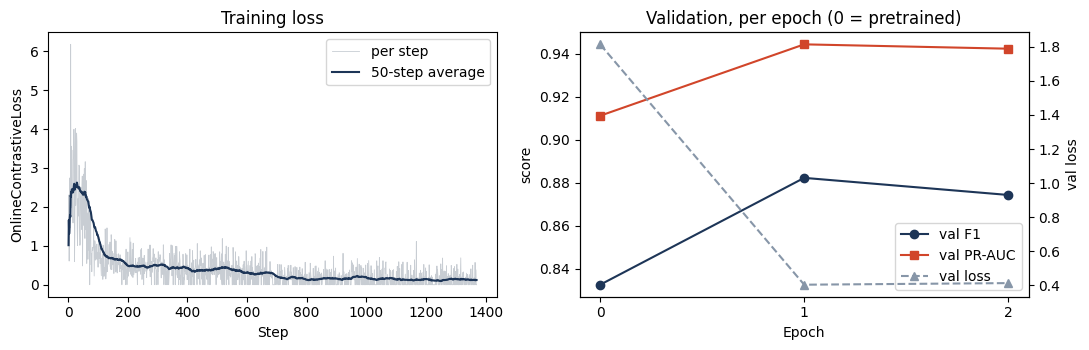

,epoch,val_loss,val_precision,val_recall,val_f1,val_accuracy,val_roc_auc,val_pr_auc,epoch_seconds
0,0,1.8144,0.8101,0.8566,0.8327,0.8442,0.9229,0.9112,0.0000
1,1,0.4035,0.8840,0.8806,0.8823,0.8937,0.9501,0.9443,41.5350
2,2,0.4129,0.8468,0.9039,0.8744,0.8825,0.9487,0.9423,40.9737


In [5]:
steps, epochs = run['steps'], run['epochs']
steps.to_csv(OUT / 'training_steps.csv', index=False)
epochs.to_csv(OUT / 'training_epochs.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(steps.step, steps.loss, color='#c8cdd3', lw=0.6, label='per step')
ax[0].plot(steps.step, steps.loss.rolling(50, min_periods=1).mean(), color='#1d3557', label='50-step average')
ax[0].set(title='Training loss', xlabel='Step', ylabel='OnlineContrastiveLoss'); ax[0].legend()
ax[1].plot(epochs.epoch, epochs.val_f1, 'o-', color='#1d3557', label='val F1')
ax[1].plot(epochs.epoch, epochs.val_pr_auc, 's-', color='#d1452a', label='val PR-AUC')
ax2 = ax[1].twinx(); ax2.plot(epochs.epoch, epochs.val_loss, '^--', color='#8796a8', label='val loss'); ax2.set_ylabel('val loss')
ax[1].set(title='Validation, per epoch (0 = pretrained)', xlabel='Epoch', ylabel='score')
ax[1].set_xticks(epochs.epoch)
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[1].legend(h1 + h2, l1 + l2, loc='lower right')
plt.tight_layout(); plt.savefig(OUT / 'learning_curves.png', dpi=160); plt.show()
epochs.round(4)

## 6. Test results on pairs

All three models scored the same way: TF-IDF and pretrained MiniLM are recomputed here exactly as in `baselines.py` (their numbers should match `baseline_metrics.csv`), then the fine-tuned model. Also broken down by edition, since the test set is mostly English.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

train_headlines = pd.unique(pd.concat([pairs['train'].headline_a, pairs['train'].headline_b]))
tfidf = TfidfVectorizer(preprocessor=lambda t: clean_headline(t).lower(), strip_accents='unicode',
                        ngram_range=(1, 2), sublinear_tf=True).fit(train_headlines)

def tfidf_scores(df):
    A, B = tfidf.transform(df.headline_a), tfidf.transform(df.headline_b)
    return np.asarray(A.multiply(B).sum(axis=1)).ravel()

pretrained = SentenceTransformer(CONFIG['base_model'], cache_folder=str(MODELS), device=DEVICE)
finetuned = SentenceTransformer(str(run['path']), device=DEVICE)
SCORERS = {'tfidf': tfidf_scores,
           'minilm_pretrained': lambda df: pair_scores(pretrained, df),
           'minilm_finetuned': lambda df: pair_scores(finetuned, df)}

rows, thresholds = [], {}
for name, scorer in SCORERS.items():
    val_s, test_s = scorer(pairs['val']), scorer(pairs['test'])
    thresholds[name] = t = best_threshold(pairs['val'].label.values, val_s)
    for split, df, s in [('val', pairs['val'], val_s), ('test', pairs['test'], test_s)]:
        for edition in ['all', 'en-CA', 'fr-CA']:
            m = np.ones(len(df), bool) if edition == 'all' else (df.edition == edition).values
            rows.append({'model': name, 'split': split, 'edition': edition, 'threshold': round(t, 4),
                         **evaluate(df.label.values[m], s[m], t), 'n_pairs': int(m.sum())})
pair_results = pd.DataFrame(rows)
pair_results.to_csv(OUT / 'pair_metrics_all_models.csv', index=False)
pair_results[(pair_results.split == 'test')].drop(columns='split').round(3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,model,edition,threshold,precision,recall,f1,accuracy,roc_auc,pr_auc,n_pairs
3,tfidf,all,0.042,0.868,0.688,0.768,0.805,0.834,0.846,2457
4,tfidf,en-CA,0.042,0.888,0.709,0.788,0.826,0.850,0.851,1853
5,tfidf,fr-CA,0.042,0.811,0.630,0.709,0.743,0.780,0.829,604
9,minilm_pretrained,all,0.294,0.893,0.836,0.863,0.876,0.947,0.945,2457
10,minilm_pretrained,en-CA,0.294,0.898,0.829,0.862,0.879,0.951,0.946,1853
11,minilm_pretrained,fr-CA,0.294,0.880,0.853,0.866,0.869,0.936,0.945,604
15,minilm_finetuned,all,0.724,0.916,0.896,0.906,0.913,0.971,0.966,2457
16,minilm_finetuned,en-CA,0.724,0.927,0.907,0.917,0.924,0.976,0.971,1853
17,minilm_finetuned,fr-CA,0.724,0.884,0.867,0.875,0.877,0.952,0.951,604


## 7. Grouping articles into cards

The real job is to group a page's articles into story cards, not just to judge pairs. For each test snapshot, every Top-stories article (including single-article cards) is grouped with agglomerative clustering (average linkage) on cosine similarity, cutting at each model's val threshold. The groups are compared with Google's cards:

- **ARI** (adjusted Rand index): 1 = identical to Google's cards, 0 = no better than random grouping.
- **Pairwise precision / recall / F1**: over all article pairs on the page, do we put together the ones Google put together?
- **Exact cards**: share of Google's cards we reproduce exactly.

In [7]:
import itertools
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

FP = ROOT / 'data' / 'google_news_front_page'
snaps = pd.read_csv(FP / 'snapshots.csv', dtype={'timestamp': str})
keep = snaps[(snaps.purpose != 'repeat') & (snaps.exclude.astype(str).str.lower() != 'true')][['timestamp', 'edition']]
arts = pd.read_csv(FP / 'front_page_articles.csv', dtype={'timestamp': str}).merge(keep, on=['timestamp', 'edition'])
arts = arts[arts.section.isin(['Top stories', 'À la une']) & arts.headline.notna()]
test_arts = arts[arts.timestamp >= '20260501000000']
print(f"Test snapshots: {test_arts.groupby(['timestamp', 'edition']).ngroups}, articles: {len(test_arts)}, "
      f"Google cards: {test_arts.groupby(['timestamp', 'edition', 'card']).ngroups}")

def similarity_matrix(name, headlines):
    if name == 'tfidf':
        X = tfidf.transform(headlines); return (X @ X.T).toarray()
    E = encode(pretrained if name == 'minilm_pretrained' else finetuned, headlines)
    return E @ E.T

def group(sim, threshold):
    if len(sim) < 2:
        return np.zeros(len(sim), int)
    dist = np.clip(1 - sim, 0, None)
    return AgglomerativeClustering(n_clusters=None, metric='precomputed', linkage='average',
                                   distance_threshold=1 - threshold).fit_predict(dist)

rows = []
for name in SCORERS:
    for (ts, ed), page in test_arts.groupby(['timestamp', 'edition']):
        truth = page.card.values
        pred = group(similarity_matrix(name, page.headline.tolist()), thresholds[name])
        same_true = [truth[i] == truth[j] for i, j in itertools.combinations(range(len(page)), 2)]
        same_pred = [pred[i] == pred[j] for i, j in itertools.combinations(range(len(page)), 2)]
        tp = sum(a and b for a, b in zip(same_true, same_pred))
        google = {frozenset(np.where(truth == c)[0]) for c in set(truth)}
        ours = {frozenset(np.where(pred == c)[0]) for c in set(pred)}
        rows.append({'model': name, 'edition': ed, 'ari': adjusted_rand_score(truth, pred),
                     'tp': tp, 'n_pred': sum(same_pred), 'n_true': sum(same_true),
                     'exact_cards': len(google & ours), 'google_cards': len(google)})
g = pd.DataFrame(rows)

def summarise(d):
    p, r = d.tp.sum() / max(d.n_pred.sum(), 1), d.tp.sum() / max(d.n_true.sum(), 1)
    return pd.Series({'ARI (mean per page)': d.ari.mean(), 'pair precision': p, 'pair recall': r,
                      'pair F1': 2 * p * r / max(p + r, 1e-12), 'exact cards': d.exact_cards.sum() / d.google_cards.sum(),
                      'pages': len(d)})

grouping = pd.concat([g.groupby('model').apply(summarise).assign(edition='all'),
                      g.groupby(['model', 'edition']).apply(summarise).reset_index('edition')]).reset_index()
grouping.to_csv(OUT / 'grouping_metrics.csv', index=False)
grouping.round(3)

Test snapshots: 112, articles: 1023, Google cards: 448


C:\Users\David\AppData\Local\Temp\ipykernel_24104\1133707176.py:48: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grouping = pd.concat([g.groupby('model').apply(summarise).assign(edition='all'),
C:\Users\David\AppData\Local\Temp\ipykernel_24104\1133707176.py:49: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  g.groupby(['model', 'edition']).apply(summarise).reset_index('edition')]).reset_index()


,model,ARI (mean per page),pair precision,pair recall,pair F1,exact cards,pages,edition
0,minilm_finetuned,0.776,0.795,0.877,0.834,0.672,112.0,all
1,minilm_pretrained,0.702,0.757,0.828,0.791,0.605,112.0,all
2,tfidf,0.640,0.798,0.679,0.733,0.576,112.0,all
3,minilm_finetuned,0.820,0.838,0.892,0.864,0.719,80.0,en-CA
4,minilm_finetuned,0.666,0.688,0.837,0.755,0.555,32.0,fr-CA
5,minilm_pretrained,0.736,0.803,0.823,0.813,0.659,80.0,en-CA
6,minilm_pretrained,0.614,0.651,0.840,0.734,0.469,32.0,fr-CA
7,tfidf,0.671,0.825,0.697,0.756,0.600,80.0,en-CA
8,tfidf,0.562,0.723,0.627,0.671,0.516,32.0,fr-CA


## 8. Ablation: training on English pairs only

Same config, but trained only on the English (`en-CA`) pairs. If the French test results drop, training on both languages is what makes the model work in French.

In [8]:
if RUN_ABLATION:
    en_train = pairs['train'][pairs['train'].edition == 'en-CA']
    print(f'English-only training pairs: {len(en_train):,} (of {len(pairs["train"]):,})')
    run_en = train(CONFIG, en_train, pairs['val'], 'minilm_finetuned_en_only')
    en_only = SentenceTransformer(str(run_en['path']), device=DEVICE)
    val_s, test_s = pair_scores(en_only, pairs['val']), pair_scores(en_only, pairs['test'])
    t = best_threshold(pairs['val'].label.values, val_s)
    rows = []
    for edition in ['all', 'en-CA', 'fr-CA']:
        m = np.ones(len(pairs['test']), bool) if edition == 'all' else (pairs['test'].edition == edition).values
        rows.append({'model': 'minilm_finetuned_en_only', 'split': 'test', 'edition': edition, 'threshold': round(t, 4),
                     **evaluate(pairs['test'].label.values[m], test_s[m], t), 'n_pairs': int(m.sum())})
    ablation = pd.concat([pair_results[(pair_results.split == 'test') & pair_results.model.isin(['minilm_pretrained', 'minilm_finetuned'])],
                          pd.DataFrame(rows)])
    ablation.to_csv(OUT / 'ablation_language.csv', index=False)
    display(ablation.pivot(index='model', columns='edition', values='f1').round(3).rename_axis(None, axis=1))

English-only training pairs: 13,416 (of 21,907)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

epoch 0 (pretrained): val F1 0.833, PR-AUC 0.911
  epoch 1 step 0/420: loss 1.6263


  epoch 1 step 100/420: loss 0.8412


  epoch 1 step 200/420: loss 0.0000


...

epoch 3: 0.4 min, val loss 0.4925, val F1 0.860, PR-AUC 0.937


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved best model to models\minilm_finetuned_en_only


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,all,en-CA,fr-CA
model,,,
minilm_finetuned,0.906,0.917,0.875
minilm_finetuned_en_only,0.886,0.895,0.858
minilm_pretrained,0.863,0.862,0.866


## 9. Training efficiency

Measured during the main run on this machine (CPU only). Inference latency, throughput and FLOPs are measured separately in Section 3.

In [9]:
size_mb = sum(f.stat().st_size for f in run['path'].rglob('*') if f.is_file()) / 1e6
e = run['epochs'][run['epochs'].epoch > 0]
efficiency = pd.Series({
    'hardware': f"{HARDWARE['gpu'] or HARDWARE['cpu']}, {HARDWARE['cpu_threads']} CPU threads, {HARDWARE['ram_gb']} GB RAM, device {HARDWARE['device']}",
    'epochs run': len(e),
    'total training time (min)': round(run['train_seconds'] / 60, 1),
    'time per epoch (min)': round(e.epoch_seconds.mean() / 60, 1),
    'steps per second': round(1 / run['steps'].seconds.mean(), 2),
    'peak memory, process (GB)': round(run['peak_rss_gb'], 2),
    'peak GPU memory (GB)': round(run['peak_vram_gb'], 2) if run['peak_vram_gb'] else 'n/a (CPU run)',
    'total parameters': run['total_params'],
    'trainable parameters': run['trainable_params'],
    'model size on disk (MB)': round(size_mb, 1),
})
efficiency.to_csv(OUT / 'training_efficiency.csv', header=['value'])
json.dump({'config': CONFIG, 'hardware': HARDWARE, 'smoke': SMOKE}, open(OUT / 'train_config.json', 'w'), indent=2)
efficiency

hardware                     NVIDIA GeForce RTX 3080, 16 CPU threads, 34.2 ...
epochs run                                                                   2
total training time (min)                                                  1.5
time per epoch (min)                                                       0.7
steps per second                                                         16.68
peak memory, process (GB)                                                 2.63
peak GPU memory (GB)                                                      1.83
total parameters                                                     117653760
trainable parameters                                                  21639552
model size on disk (MB)                                                  487.7
dtype: object

## Using the fine-tuned model elsewhere

```python
from src.embeddings import similarity, embed_headlines
s = similarity(a, b, model_name=str(ROOT / 'models' / 'minilm_finetuned'))
```

The model folder is not in git (about 470 MB). Re-run this notebook to create it, or get the folder from the team drive.